# ComplaintRouter — Exploratory Data Analysis

This notebook explores the cleaned CFPB consumer complaint data used for
ComplaintRouter. The analysis examines product class balance, complaint
narrative length, frequent terms across product categories, and other
characteristics relevant to the classification task.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
data_path = Path("../data/processed/complaint_router_modeling_data.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Number of product classes:", df["Product"].nunique())
print("clean_narrative present:", "clean_narrative" in df.columns)

df.head()

Dataset shape: (162500, 11)
Number of product classes: 11
clean_narrative present: True


,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company,Company response to consumer,Timely response?,Complaint ID,clean_narrative
0,2025-09-05,Debt collection,I do not know,Attempts to collect debt not owed,Debt was result of identity theft,XXXX XXXX AND MIDLAND CREDis falsely reportin...,ENCORE CAPITAL GROUP INC.,Closed with non-monetary relief,Yes,15737202,and midland credis falsely reporting on my cre...
1,2025-06-10,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,I am submitting this complaint against CREDHUB...,"CredHub, Inc",Closed with explanation,Yes,13970771,i am submitting this complaint against credhub...
2,2024-02-13,Credit card,General-purpose credit card or charge card,Getting a credit card,Delay in processing application,Somebody requested an capital one credit card ...,CAPITAL ONE FINANCIAL CORPORATION,Closed with explanation,Yes,8338657,somebody requested an capital one credit card ...
3,2025-01-16,Checking or savings account,Checking account,Problem caused by your funds being low,Overdrafts and overdraft fees,I am writing to file a complaint against Navy ...,NAVY FEDERAL CREDIT UNION,Closed with explanation,Yes,11584582,i am writing to file a complaint against navy ...
4,2025-12-28,"Money transfer, virtual currency, or money ser...",Domestic (US) money transfer,Other transaction problem,NaN,I am seeking assistance in recovering {$200.00...,"Paypal Holdings, Inc",Closed with explanation,Yes,18331559,i am seeking assistance in recovering {$200. }...


In [3]:
df = df.dropna(subset=["clean_narrative"]).copy()

df = df[
    df["clean_narrative"].str.strip() != ""
].copy()

print("Dataset after removing empty cleaned narratives:", df.shape)

Dataset after removing empty cleaned narratives: (162494, 11)


## 1. Product Class Distribution

We first examine the number of complaints represented by each financial
product category in the modeling dataset.

In [4]:
product_counts = df["Product"].value_counts()

print(product_counts)

Product
Credit reporting or other personal consumer reports        34994
Debt collection                                            25000
Credit card                                                20000
Checking or savings account                                20000
Money transfer, virtual currency, or money service         15000
Vehicle loan or lease                                      10000
Student loan                                               10000
Mortgage                                                   10000
Payday loan, title loan, personal loan, or advance loan     7500
Debt or credit management                                   5000
Prepaid card                                                5000
Name: count, dtype: int64


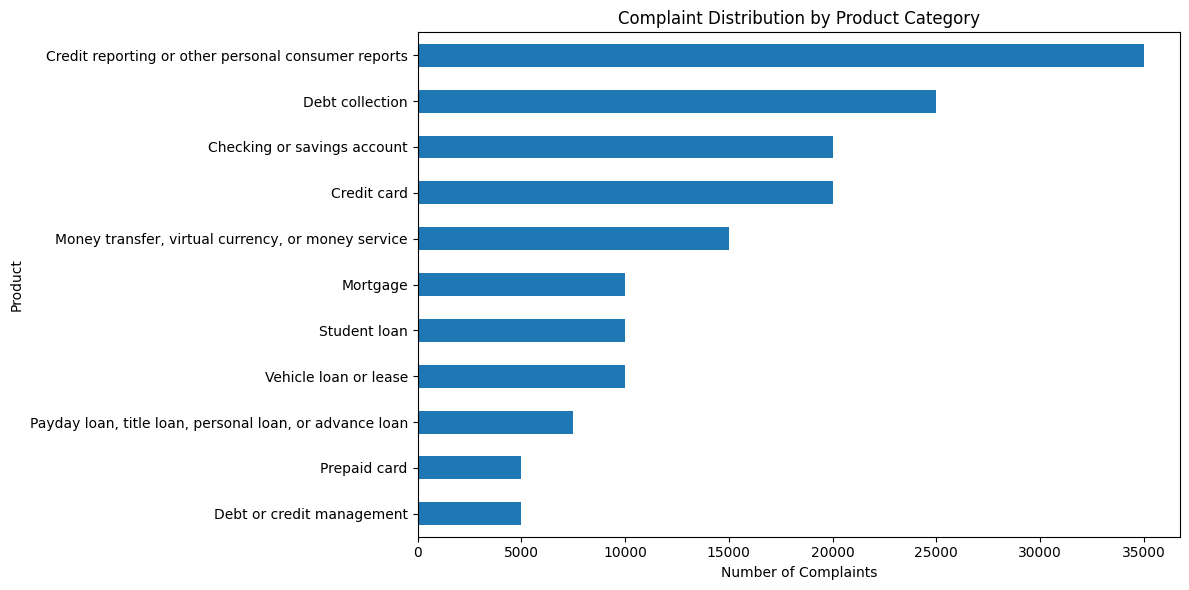

In [5]:
plt.figure(figsize=(12, 6))

product_counts.sort_values().plot(kind="barh")

plt.title("Complaint Distribution by Product Category")
plt.xlabel("Number of Complaints")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "../figures/product_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The modeling dataset contains all 11 product categories but uses capped
sampling to reduce the dominance of the largest classes. Credit reporting remains the largest category, while smaller categories such as prepaid cards and debt or credit management remain sufficiently represented for classification.

## 2. Complaint Narrative Length

In [6]:
df["narrative_word_count"] = (
    df["Consumer complaint narrative"]
    .astype(str)
    .str.split()
    .str.len()
)

print(df["narrative_word_count"].describe())

count    162494.000000
mean        216.872783
std         243.846696
min           2.000000
25%          83.000000
50%         157.000000
75%         273.000000
max        5911.000000
Name: narrative_word_count, dtype: float64


In [7]:
length_by_product = (
    df.groupby("Product")["narrative_word_count"]
    .agg(["mean", "median", "min", "max"])
    .round(1)
    .sort_values("median", ascending=False)
)

length_by_product

,mean,median,min,max
Product,,,,
Mortgage,302.2,221.0,2,5557
Vehicle loan or lease,240.2,185.0,4,4658
Credit card,230.3,177.0,3,5911
Student loan,222.2,169.0,5,3960
Checking or savings account,217.4,160.0,4,5347
Credit reporting or other personal consumer reports,225.0,158.0,2,5783
"Payday loan, title loan, personal loan, or advance loan",209.7,158.0,3,3925
Debt collection,190.4,136.0,2,5736
Prepaid card,182.5,136.0,4,4302


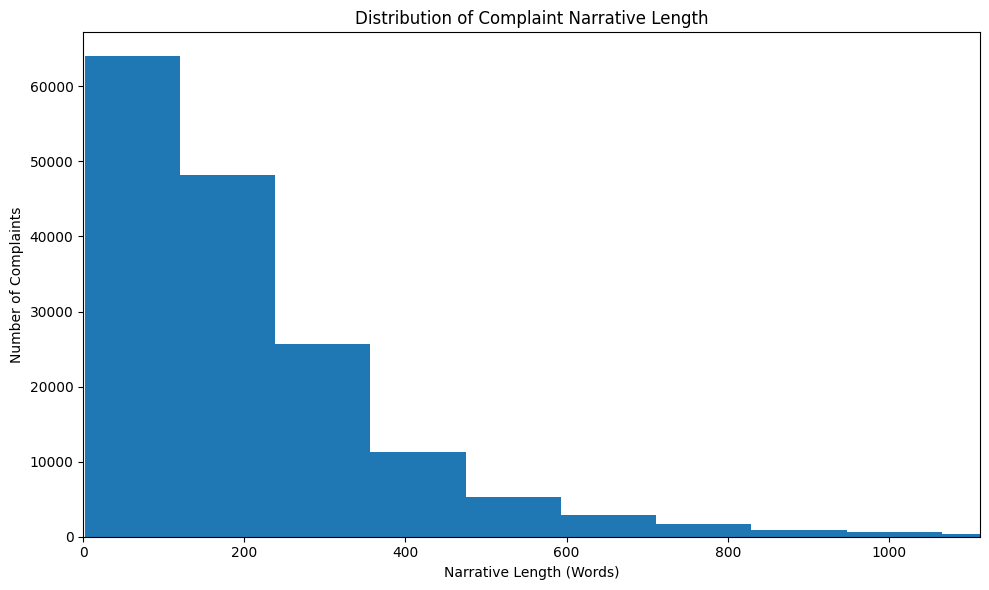

In [8]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["narrative_word_count"],
    bins=50
)

plt.title("Distribution of Complaint Narrative Length")
plt.xlabel("Narrative Length (Words)")
plt.ylabel("Number of Complaints")
plt.xlim(0, df["narrative_word_count"].quantile(0.99))
plt.tight_layout()

plt.savefig(
    "../figures/narrative_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Narrative Length Findings

Complaint narratives are right-skewed, with a median length of 157 words and
a mean of approximately 217 words. Most complaints contain fewer than 400
words, although a small number of substantially longer narratives create a
long right tail. Narrative length also varies across product categories, with
mortgage complaints having the highest median length among the examined
categories.

In [9]:
print(df.shape)
print(df.columns.tolist())
print("clean_narrative" in df.columns)

(162494, 12)
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company', 'Company response to consumer', 'Timely response?', 'Complaint ID', 'clean_narrative', 'narrative_word_count']
True


In [10]:
print("Missing clean narratives:", df["clean_narrative"].isna().sum())
print("Empty clean narratives:", (df["clean_narrative"].fillna("").str.strip() == "").sum())

Missing clean narratives: 0
Empty clean narratives: 0


In [11]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=5
)

tfidf_matrix = vectorizer.fit_transform(
    df["clean_narrative"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (162494, 5000)


In [12]:
import numpy as np

feature_names = np.array(vectorizer.get_feature_names_out())

top_terms_by_product = {}

for product in df["Product"].unique():

    product_indices = df["Product"] == product

    mean_scores = np.asarray(
        tfidf_matrix[product_indices].mean(axis=0)
    ).ravel()

    top_indices = mean_scores.argsort()[-10:][::-1]

    top_terms_by_product[product] = feature_names[top_indices]

In [13]:
top_terms_df = pd.DataFrame.from_dict(
    top_terms_by_product,
    orient="index"
)

top_terms_df.columns = [
    f"Term {i}" for i in range(1, 11)
]

top_terms_df

,Term 1,Term 2,Term 3,Term 4,Term 5,Term 6,Term 7,Term 8,Term 9,Term 10
Debt collection,debt,credit,collection,account,report,reporting,validation,information,company,original
Credit reporting or other personal consumer reports,credit,report,information,reporting,consumer,accounts,account,15,inquiries,fcra
Credit card,card,credit,account,bank,payment,capital,charge,charges,balance,year
Checking or savings account,account,bank,funds,money,check,chase,transactions,deposit,told,card
"Money transfer, virtual currency, or money service",app,cash,account,zelle,money,funds,transfer,unfair,financial,resolution
Vehicle loan or lease,vehicle,car,loan,payment,credit,payments,repossession,auto,account,paid
Debt or credit management,credit,debt,account,company,report,paid,settlement,information,payments,payment
Student loan,loans,loan,mohela,student,payment,payments,forbearance,nelnet,school,repayment
Mortgage,mortgage,loan,payment,escrow,insurance,home,payments,property,company,foreclosure
Prepaid card,card,gift,use,cards,money,tried,amex,account,declined,express


## Relief Rate by Product

To examine complaint outcomes, company response categories are first reviewed to determine which responses indicate that the consumer received some form of relief.

In [14]:
response_counts = df["Company response to consumer"].value_counts()

print(response_counts)

Company response to consumer
Closed with explanation            125179
Closed with non-monetary relief     26211
Closed with monetary relief          9063
Untimely response                    2003
In progress                            37
Name: count, dtype: int64


In [15]:
relief_responses = [
    "Closed with monetary relief",
    "Closed with non-monetary relief"
]

df["received_relief"] = (
    df["Company response to consumer"]
    .isin(relief_responses)
)

print(df["received_relief"].value_counts())

received_relief
False    127220
True      35274
Name: count, dtype: int64


## Consumer Relief by Product Category

This analysis compares the percentage of complaints that resulted in either
monetary or non-monetary relief across product categories.

In [16]:
relief_by_product = (
    df.groupby("Product")["received_relief"]
      .agg(["count", "sum", "mean"])
)

relief_by_product.columns = [
    "Total Complaints",
    "Complaints with Relief",
    "Relief Rate"
]

relief_by_product["Relief Rate"] = (
    relief_by_product["Relief Rate"] * 100
).round(2)

relief_by_product = relief_by_product.sort_values(
    "Relief Rate",
    ascending=False
)

relief_by_product

,Total Complaints,Complaints with Relief,Relief Rate
Product,,,
Credit reporting or other personal consumer reports,34994,15163,43.33
Credit card,20000,6010,30.05
Prepaid card,5000,1217,24.34
Debt collection,25000,5112,20.45
Checking or savings account,20000,3743,18.72
Debt or credit management,5000,637,12.74
"Money transfer, virtual currency, or money service",15000,1273,8.49
Vehicle loan or lease,10000,828,8.28
"Payday loan, title loan, personal loan, or advance loan",7500,554,7.39


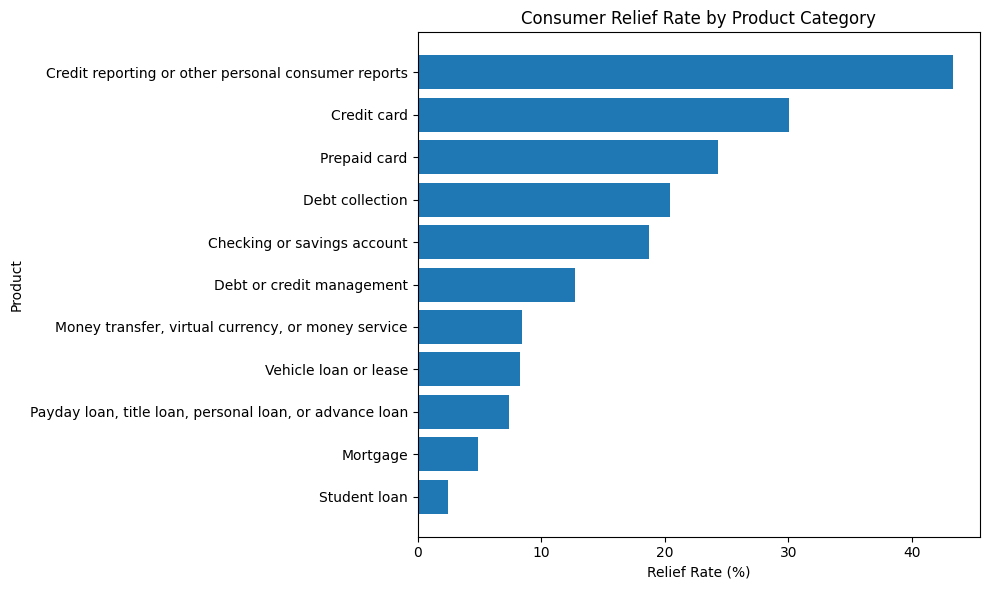

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    relief_by_product.index,
    relief_by_product["Relief Rate"]
)

plt.xlabel("Relief Rate (%)")
plt.ylabel("Product")
plt.title("Consumer Relief Rate by Product Category")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()